# Durham, NC and similar-sized metros

How does housing affordability in the Durham–Chapel Hill metro compare with the 10 metros closest to it in population? And how have incomes kept pace with housing costs?

**Peers** are chosen automatically: the 10 metro areas whose latest Census population is closest to Durham's (on a log scale). Change them with `python scripts/build_data.py --focus ... --peers N`. Raleigh, Durham's larger neighbour, is in the top-50 set and shown for context.

**Income caveat:** ACS 1-year incomes are survey estimates. For metros this size the 90% margin of error is roughly ±$2–5k, so year-to-year moves of a few percent can be noise. Chart 2 shades that range.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from housing import load_processed
from housing.metrics import COST_BURDEN_LINE

data = load_processed()
annual, latest = data["annual"], data["latest"]
FOCUS = annual.loc[annual["group"] == "focus", "metro"].iloc[0]
NEIGHBOUR = "Raleigh, NC"
cohort = ["focus", "peer"]
first, last = annual["year"].min(), annual["year"].max()

# Reference palette: categorical slots in fixed order, recessive text and grid.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, MUTED, GRID, SURFACE, GRAY = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#b8b7b1"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlelocation": "left",
    "axes.titlesize": 13, "axes.axisbelow": True, "axes.titleweight": "bold", "font.size": 10,
})
pct = mtick.PercentFormatter(1.0, decimals=0)
as_of = f"{latest['date'].max():%B %Y}"
GROUPS = [("top", GRAY, "Top 50 metros", 2), ("peer", BLUE, "Similar-sized peers", 3), ("focus", ORANGE, FOCUS, 4)]
print(f"Focus: {FOCUS}. Prices and rates as of {as_of}; income from ACS {latest['income_year'].iloc[0]}")
print("Peers:", ", ".join(latest.loc[latest["group"] == "peer"].sort_values("population", ascending=False)["metro"]))

Focus: Durham, NC. Prices and rates as of September 2026; income from ACS 2025
Peers: Palm Bay, FL, Wichita, KS, Syracuse, NY, Augusta, GA, Fayetteville, AR, Harrisburg, PA, Jackson, MS, Spokane, WA, Toledo, OH, Chattanooga, TN


## 1. Affordability today: Durham vs its peers

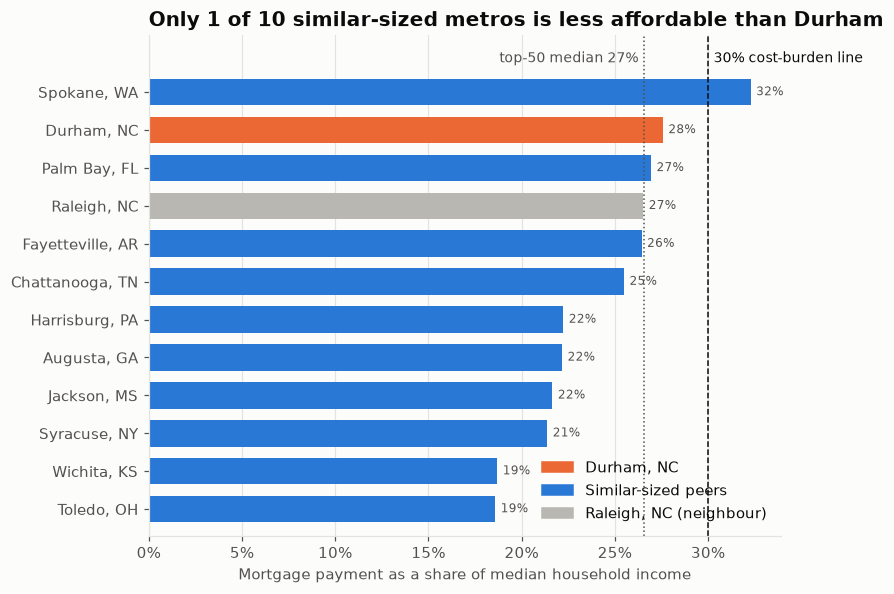

In [2]:
d = latest[latest["group"].isin(cohort) | (latest["metro"] == NEIGHBOUR)].sort_values("payment_to_income")
top50_median = latest.loc[latest["group"] == "top", "payment_to_income"].median()
peers_only = d[d["group"] == "peer"]
focus_share = d.loc[d["metro"] == FOCUS, "payment_to_income"].iloc[0]
less_affordable = (peers_only["payment_to_income"] > focus_share).sum()

fig, ax = plt.subplots(figsize=(8, 5.5))
colors = [ORANGE if m == FOCUS else GRAY if m == NEIGHBOUR else BLUE for m in d["metro"]]
ax.barh(d["metro"], d["payment_to_income"], color=colors, height=0.7)
for y, v in enumerate(d["payment_to_income"]):
    ax.text(v + 0.003, y, f"{v:.0%}", va="center", fontsize=8, color=MUTED)
ax.axvline(COST_BURDEN_LINE, color=INK, linewidth=1, linestyle="--")
ax.axvline(top50_median, color=MUTED, linewidth=1, linestyle=":")
ax.text(COST_BURDEN_LINE + 0.003, len(d) - 0.3, "30% cost-burden line", fontsize=9, va="bottom")
ax.text(top50_median - 0.003, len(d) - 0.3, f"top-50 median {top50_median:.0%}", fontsize=9, color=MUTED, va="bottom", ha="right")
ax.set_ylim(-0.7, len(d) + 0.5)
ax.xaxis.set_major_formatter(pct)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Mortgage payment as a share of median household income")
verb = "is" if less_affordable == 1 else "are"
ax.set_title(f"Only {less_affordable} of {len(peers_only)} similar-sized metros {verb} less affordable than {FOCUS.split(',')[0]}")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in (ORANGE, BLUE, GRAY)],
          labels=[FOCUS, "Similar-sized peers", f"{NEIGHBOUR} (neighbour)"], frameon=False, loc="lower right")
plt.tight_layout()

## 2. Have Durham incomes kept up with housing costs?

Everything is indexed so the first year = 100. The shaded band is the income estimate's 90% margin of error.

      median_income  median_income_moe  home_value     rent  monthly_payment  payment_to_income
year                                                                                           
2021          71601               1955   323679.32  1349.41          1085.54               0.18
2022          79154               3994   392377.10  1519.29          1748.48               0.27
2023          83280               3695   399990.65  1568.69          2085.13               0.30
2024          83542               3589   414347.23  1584.31          2144.16               0.31
2025          91715               4328   413889.77  1598.72          2113.77               0.28


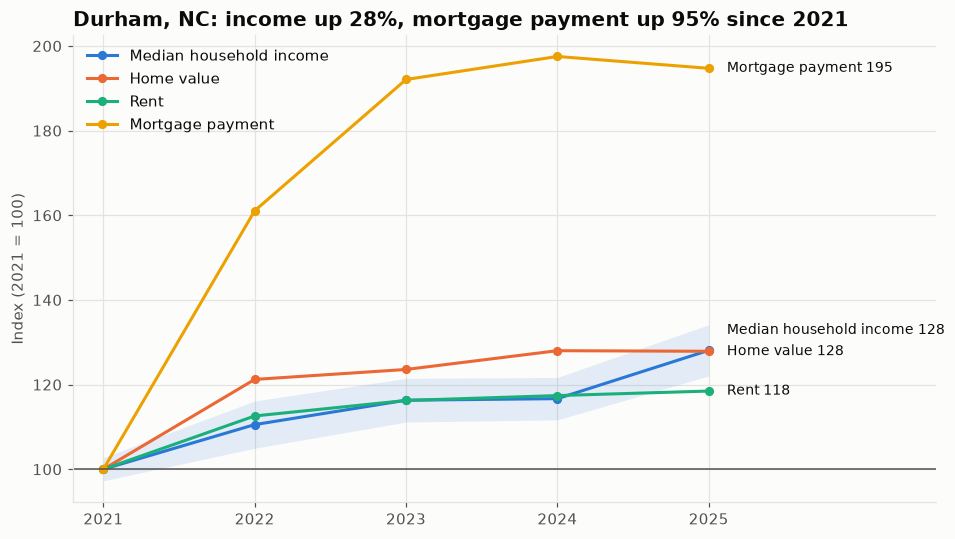

In [3]:
f = annual[annual["metro"] == FOCUS].set_index("year")
series = {"Median household income": ("median_income_index", BLUE),
          "Home value": ("home_value_index", ORANGE),
          "Rent": ("rent_index", AQUA),
          "Mortgage payment": ("monthly_payment_index", YELLOW)}

fig, ax = plt.subplots(figsize=(9, 5))
base = f["median_income"].iloc[0]
ax.fill_between(f.index, (f["median_income"] - f["median_income_moe"]) / base * 100,
                (f["median_income"] + f["median_income_moe"]) / base * 100, color=BLUE, alpha=0.12, linewidth=0)
for label, (col, color) in series.items():
    ax.plot(f.index, f[col], color=color, linewidth=2, marker="o", markersize=5, label=label)
# End labels, nudged apart so lines that finish at the same value stay readable.
ends = sorted(((f[col].iloc[-1], label) for label, (col, _) in series.items()))
placed = []
for value, label in ends:
    y = max(value, placed[-1] + 5) if placed else value
    placed.append(y)
    ax.annotate(f"{label} {value:.0f}", (f.index[-1], value), xytext=(f.index[-1] + 0.12, y),
                textcoords="data", va="center", fontsize=9)
ax.axhline(100, color=MUTED, linewidth=1)
ax.set_xticks(f.index)
ax.set_xlim(f.index[0] - 0.2, f.index[-1] + 1.5)
ax.set_ylabel(f"Index ({first} = 100)")
ax.legend(frameon=False, loc="upper left")
ax.set_title(f"{FOCUS}: income up {f['median_income_index'].iloc[-1] - 100:.0f}%, "
             f"mortgage payment up {f['monthly_payment_index'].iloc[-1] - 100:.0f}% since {first}")
plt.tight_layout()
print(f["median_income median_income_moe home_value rent monthly_payment payment_to_income".split()].round(2).to_string())

## 3. Income vs home value growth across the cohort

Each panel is one metro. Where the orange line sits above the blue, home prices have grown faster than incomes.

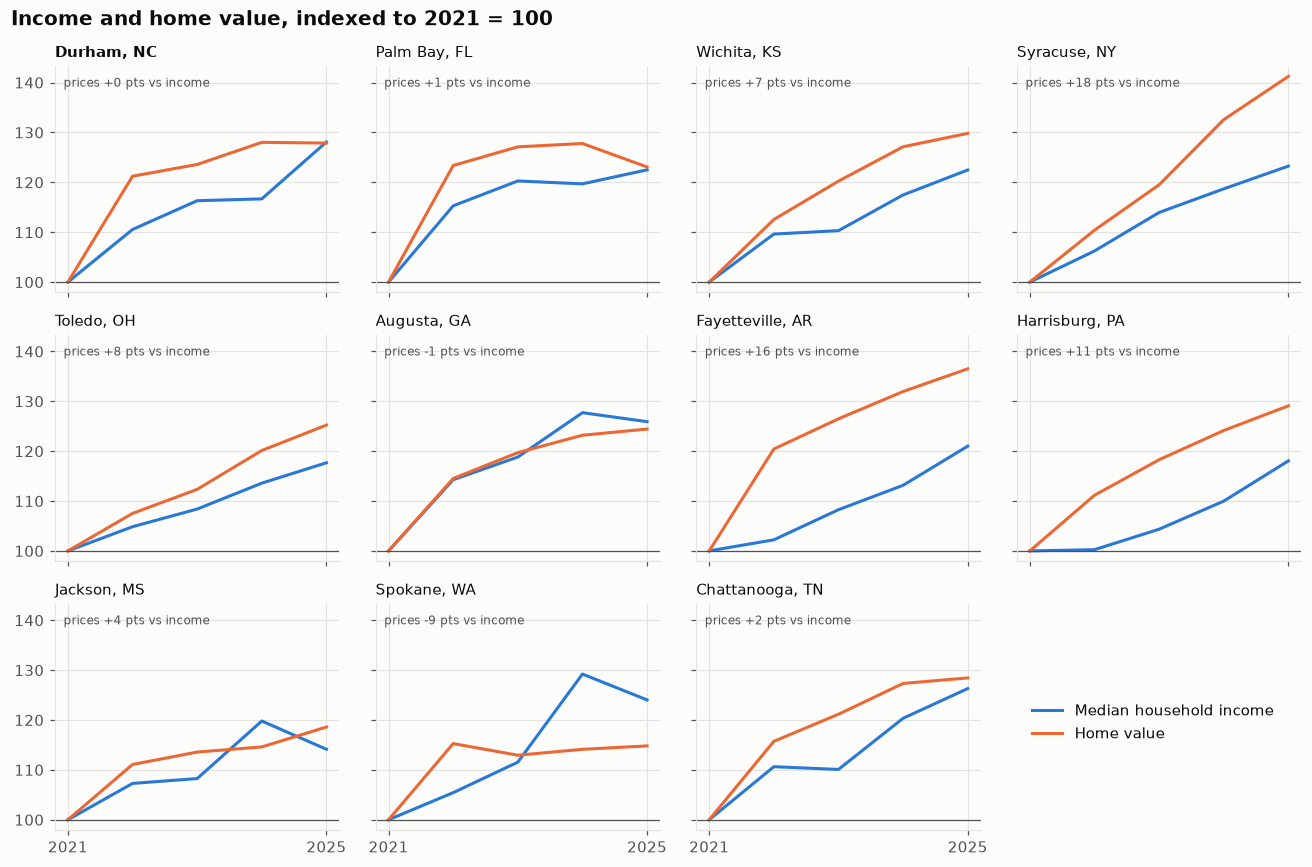

In [4]:
c = annual[annual["group"].isin(cohort)]
order = [FOCUS] + c[c["group"] == "peer"].sort_values("population", ascending=False)["metro"].unique().tolist()
fig, axes = plt.subplots(3, 4, figsize=(12, 8), sharex=True, sharey=True)
for ax, metro in zip(axes.flat, order):
    m = c[c["metro"] == metro]
    ax.plot(m["year"], m["median_income_index"], color=BLUE, linewidth=2)
    ax.plot(m["year"], m["home_value_index"], color=ORANGE, linewidth=2)
    ax.axhline(100, color=MUTED, linewidth=0.8)
    gap = round(m["home_value_index"].iloc[-1] - m["median_income_index"].iloc[-1]) + 0  # + 0 turns -0 into 0
    ax.set_title(metro, fontsize=10, fontweight="bold" if metro == FOCUS else "normal", loc="left")
    ax.text(0.03, 0.95, f"prices {gap:+.0f} pts vs income", transform=ax.transAxes, fontsize=8, color=MUTED, va="top")
    ax.set_xticks([first, last])
for ax in axes.flat[len(order):]:
    ax.axis("off")
fig.legend(handles=[plt.Line2D([], [], color=BLUE, lw=2), plt.Line2D([], [], color=ORANGE, lw=2)],
           labels=["Median household income", "Home value"], loc="center", bbox_to_anchor=(0.875, 0.17), frameon=False)
fig.suptitle(f"Income and home value, indexed to {first} = 100", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout()

## 4. Across all metros: did prices outrun incomes?

Points above the diagonal are metros where home values grew faster than median income.

Correlation between income growth and home value growth: r = 0.32


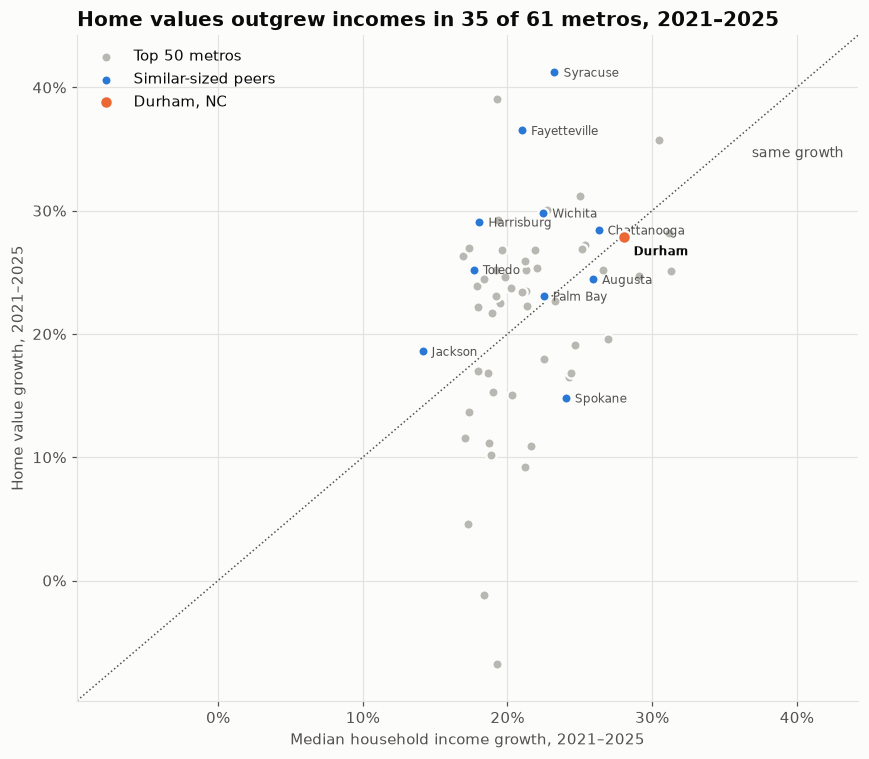

In [5]:
w = annual[annual["year"] == last].copy()
w["income_growth"] = w["median_income_index"] / 100 - 1
w["value_growth"] = w["home_value_index"] / 100 - 1

fig, ax = plt.subplots(figsize=(8, 7))
for grp, color, label, z in GROUPS:
    g = w[w["group"] == grp]
    ax.scatter(g["income_growth"], g["value_growth"], color=color, s=70 if grp == "focus" else 45,
               edgecolor=SURFACE, linewidth=1.5, zorder=z, label=label)
lo = min(w["income_growth"].min(), w["value_growth"].min()) - 0.03
hi = max(w["income_growth"].max(), w["value_growth"].max()) + 0.03
ax.plot([lo, hi], [lo, hi], color=MUTED, linewidth=1, linestyle=":")
ax.text(hi - 0.01, hi - 0.09, "same growth", color=MUTED, fontsize=9, ha="right", va="top")
for _, r in w[w["group"].isin(cohort)].iterrows():
    is_focus = r["group"] == "focus"
    ax.annotate(r["metro"].split(",")[0], (r["income_growth"], r["value_growth"]), xytext=(6, -12 if is_focus else -3),
                textcoords="offset points", fontsize=8, color=INK if is_focus else MUTED,
                fontweight="bold" if is_focus else "normal")
ax.set(xlim=(lo, hi), ylim=(lo, hi))
ax.xaxis.set_major_formatter(pct)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel(f"Median household income growth, {first}–{last}")
ax.set_ylabel(f"Home value growth, {first}–{last}")
ax.legend(frameon=False, loc="upper left")
outran = (w["value_growth"] > w["income_growth"]).sum()
ax.set_title(f"Home values outgrew incomes in {outran} of {len(w)} metros, {first}–{last}")
plt.tight_layout()
r = np.corrcoef(w["income_growth"], w["value_growth"])[0, 1]
print(f"Correlation between income growth and home value growth: r = {r:.2f}")

## 5. Do higher-income metros have pricier homes?

The cross-section for the latest income year. The dashed line is a least-squares fit; a metro above it has expensive homes *for its income level*.

Each extra $1,000 of median income goes with ~$11,785 more home value.
Durham, NC: $413,890 actual vs $437,356 expected for its income (-23,467).


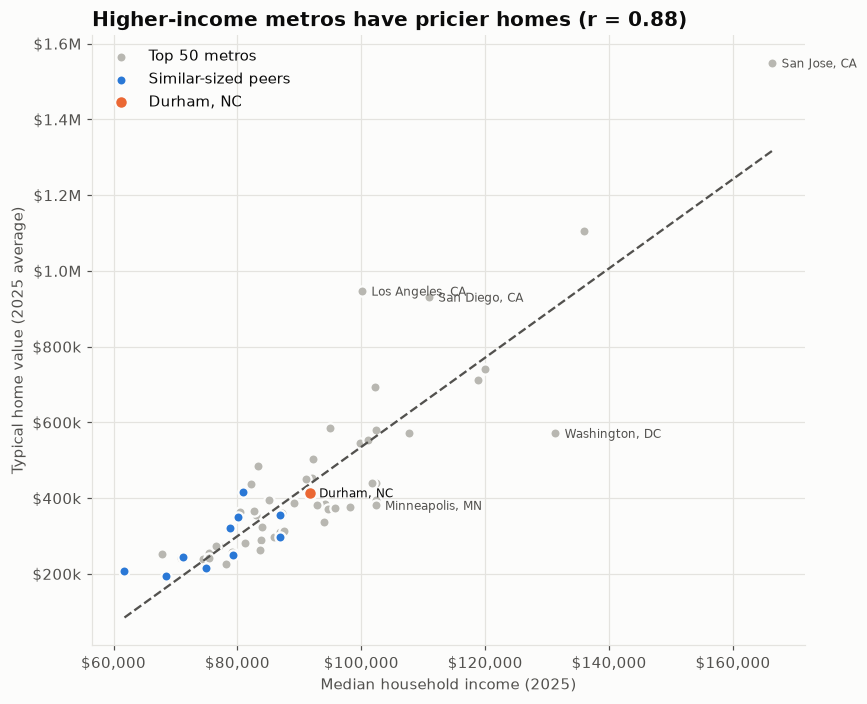

In [6]:
fig, ax = plt.subplots(figsize=(8, 6.5))
for grp, color, label, z in GROUPS:
    g = w[w["group"] == grp]
    ax.scatter(g["median_income"], g["home_value"], color=color, s=70 if grp == "focus" else 45,
               edgecolor=SURFACE, linewidth=1.5, zorder=z, label=label)
slope, intercept = np.polyfit(w["median_income"], w["home_value"], 1)
xs = np.linspace(w["median_income"].min(), w["median_income"].max(), 50)
ax.plot(xs, slope * xs + intercept, color=MUTED, linewidth=1.5, linestyle="--")
w["vs_fit"] = w["home_value"] - (slope * w["median_income"] + intercept)
for idx in dict.fromkeys([*w["vs_fit"].nlargest(3).index, *w["vs_fit"].nsmallest(2).index, *w[w["group"] == "focus"].index]):
    r_ = w.loc[idx]
    ax.annotate(r_["metro"], (r_["median_income"], r_["home_value"]), xytext=(6, -3), textcoords="offset points",
                fontsize=8, color=INK if r_["group"] == "focus" else MUTED)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v/1e6:.1f}M" if v >= 1e6 else f"${v/1e3:.0f}k"))
ax.set_xlabel(f"Median household income ({last})")
ax.set_ylabel(f"Typical home value ({last} average)")
ax.legend(frameon=False, loc="upper left")
corr = np.corrcoef(w["median_income"], w["home_value"])[0, 1]
ax.set_title(f"Higher-income metros have pricier homes (r = {corr:.2f})")
plt.tight_layout()
fv = w.loc[w["group"] == "focus"].iloc[0]
print(f"Each extra $1,000 of median income goes with ~${slope*1000:,.0f} more home value.")
print(f"{FOCUS}: ${fv['home_value']:,.0f} actual vs ${fv['home_value'] - fv['vs_fit']:,.0f} expected for its income ({fv['vs_fit']:+,.0f}).")

## Summary table

In [7]:
t = w[w["group"].isin(cohort)].copy()
for col in ["median_income", "home_value", "rent"]:
    t[f"{col}_change"] = t[f"{col}_index"] / 100 - 1
cols = ["metro", "population", "median_income", "home_value", "rent", "price_to_income", "payment_to_income",
        "median_income_change", "home_value_change", "rent_change"]
(t.sort_values("payment_to_income", ascending=False)[cols].set_index("metro")
 .style.format({"population": "{:,.0f}", "median_income": "${:,.0f}", "home_value": "${:,.0f}", "rent": "${:,.0f}",
                "price_to_income": "{:.1f}", "payment_to_income": "{:.0%}", "median_income_change": "{:+.0%}",
                "home_value_change": "{:+.0%}", "rent_change": "{:+.0%}"})
 .set_caption(f"{last} annual averages; changes since {first}"))

,population,median_income,home_value,rent,price_to_income,payment_to_income,median_income_change,home_value_change,rent_change
metro,,,,,,,,,
"Spokane, WA","608,012","$80,969","$415,918","$1,452",5.1,31%,+24%,+15%,+16%
"Durham, NC","625,485","$91,715","$413,890","$1,599",4.5,28%,+28%,+28%,+18%
"Palm Bay, FL","663,982","$80,032","$348,796","$1,855",4.4,27%,+22%,+23%,+23%
"Fayetteville, AR","621,366","$86,840","$354,604","$1,541",4.1,25%,+21%,+37%,+30%
"Chattanooga, TN","593,468","$78,790","$320,911","$1,466",4.1,25%,+26%,+28%,+22%
"Augusta, GA","642,511","$71,159","$243,983","$1,411",3.4,21%,+26%,+24%,+25%
"Harrisburg, PA","617,427","$86,837","$295,926","$1,422",3.4,21%,+18%,+29%,+24%
"Jackson, MS","611,499","$61,772","$207,079","$1,400",3.4,21%,+14%,+19%,+23%
"Syracuse, NY","652,273","$79,246","$249,322","$1,559",3.1,19%,+23%,+41%,+32%
